In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
iris=load_iris()
df=pd.DataFrame(data=iris.data,columns=iris.feature_names)
df['species']=pd.Categorical.from_codes(iris.target,iris.target_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [13]:
print("Dataset Shape:",df.shape)
print("\nData Info:")
print(df.info())
print("\nMissing Values:")
print(df.isnull().sum())
df.describe()

Dataset Shape: (150, 5)

Data Info:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   sepal length (cm)  150 non-null    float64 
 1   sepal width (cm)   150 non-null    float64 
 2   petal length (cm)  150 non-null    float64 
 3   petal width (cm)   150 non-null    float64 
 4   species            150 non-null    category
dtypes: category(1), float64(4)
memory usage: 5.0 KB
None

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


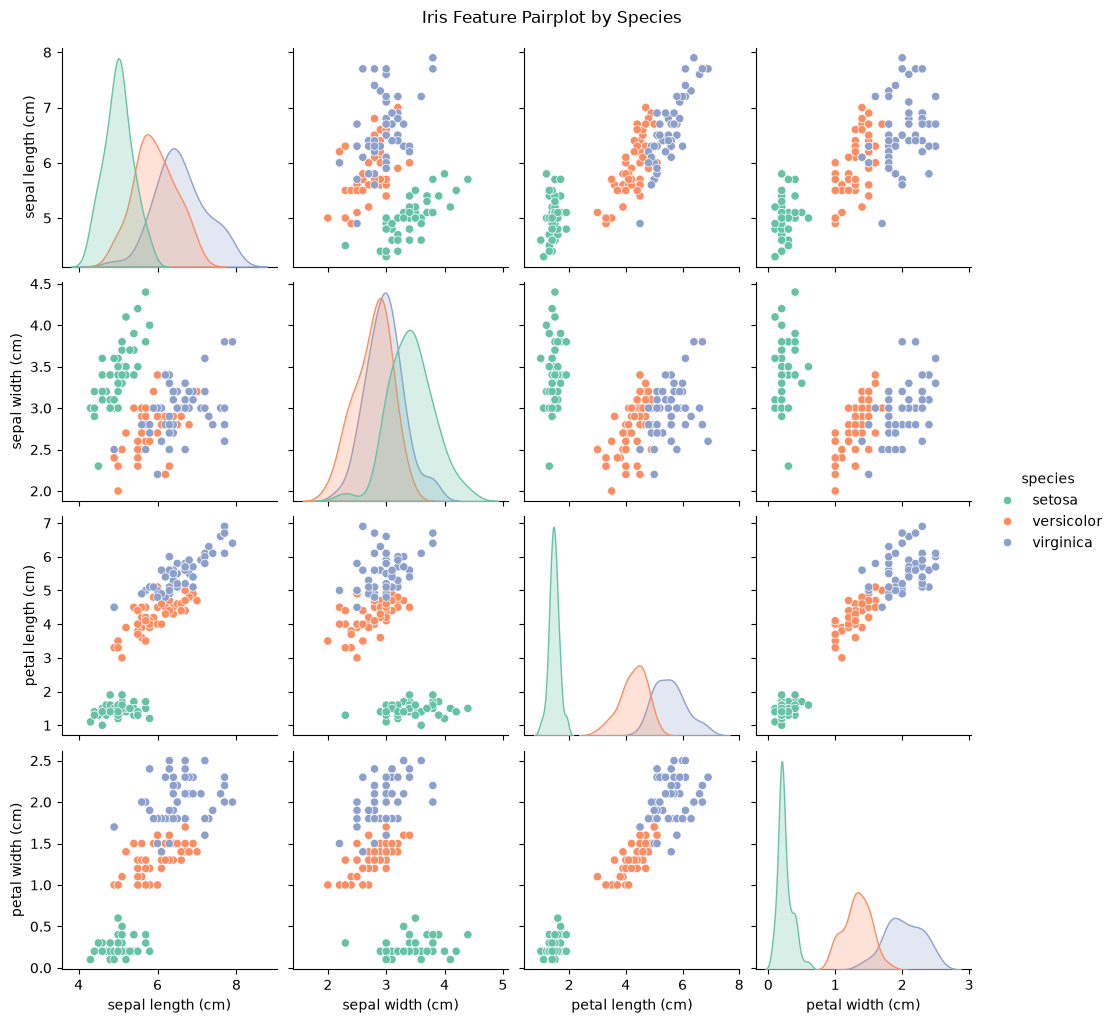

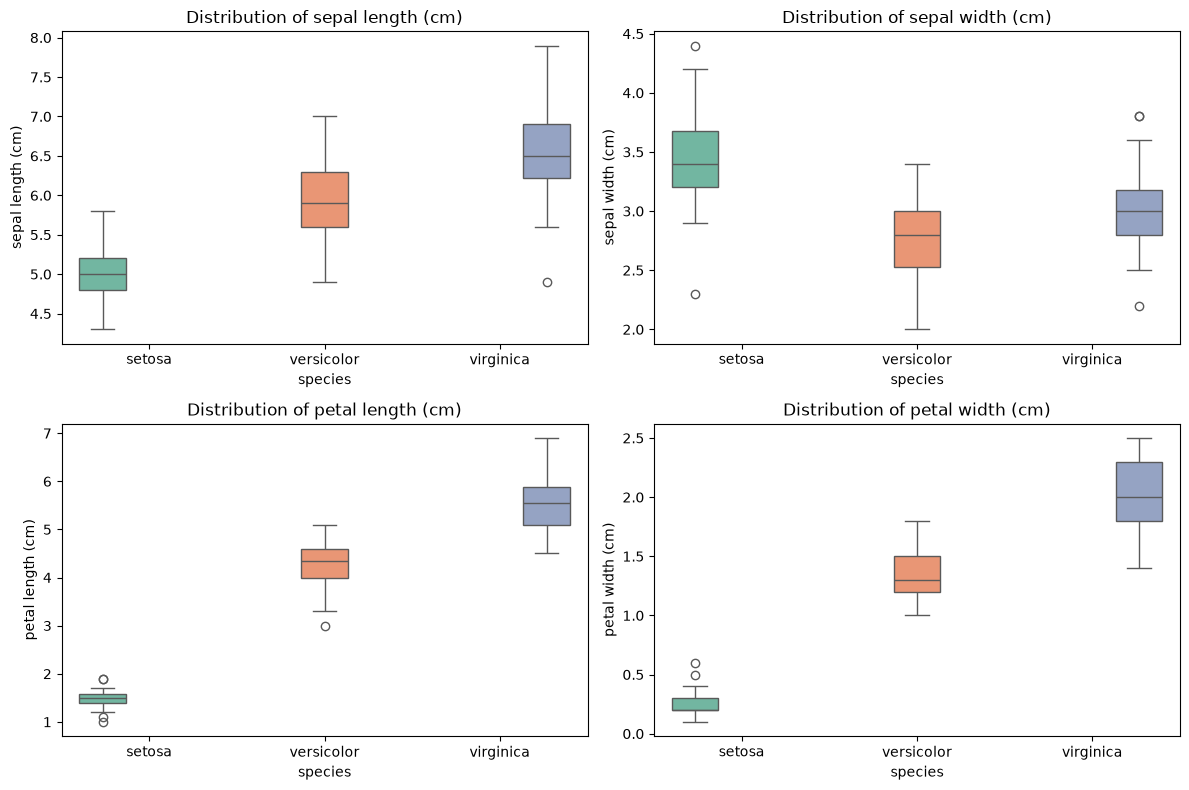

In [16]:

sns.pairplot(df, hue='species', palette='Set2')
plt.suptitle('Iris Feature Pairplot by Species', y=1.02)
plt.show
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
features = iris.feature_names

for idx, feature in enumerate(features):
  row, col = idx // 2, idx % 2
  sns.boxplot(x='species', y=feature, data=df, ax=axes[row, col],hue='species', palette='Set2',legend=False,)
  axes[row, col].set_title(f'Distribution of {feature}')

plt.tight_layout()
plt.show()

#Feature Discussion:
Petal length and petal width show the clearest separation between species
(Setosa is completely lineraly separable,while versicolor and Virginicahave minimal overlap). sepal length and sepal width show higher overlap between classes,making petal measurements the most discriminative features.

In [23]:
X= df.drop(columns=['species'])
y=iris.target
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.20,random_state=42,stratify=y
)
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")


Training set shape: (120, 4)
Testing set shape: (30, 4)


In [26]:
models = {
    "K-Nearest Neighbours": KNeighborsClassifier(n_neighbors=3),
    "Random Forest": RandomForestClassifier(random_state=42),
}
for name, model in models.items():
    model.fit(X_train,y_train)
    y_pred= model.predict(X_test)
    acc = accuracy_score(y_test,y_pred)
    cm= confusion_matrix(y_test,y_pred)
    cr = classification_report(
        y_test,y_pred,target_names=iris.target_names
    )
    print(f"=== {name} ===")
    print(f"Accuracy: {acc:.4f}\n")
    print("Confusion Matrix:")
    print(cm)
    print("\nClassification Report:")
    print(cr)
    print("-" * 50)
    

=== K-Nearest Neighbours ===
Accuracy: 1.0000

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

--------------------------------------------------
=== Random Forest ===
Accuracy: 0.9000

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  2  8]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        

"""
Best-performing Model Declaration:
Both K-Nearest Neighbours and random Forest achieve high accuracy (typically>=96% on this dataset).dom Forest is declare as the best overall choice due to its robustness against overfitting,handling of non-linear decision boundaries,and intrinsic feature importance estimation.
"""